# **Practical assignment for Topic 11**

In the assignment, you have to use the dataset `auto-lpkm.tsv` given in the lecture and you should use the **gplearn** library.
<br>
<br>

**Task 1**<br>
Look through the available algorithm configuration options and perform systematic exploration of hyperparameter values with the goal of maximizing the predictive performance of the model, as well as to determine hyperparameter influence on the results. You have to sistematically work with at least four hyperparameters.

Special notes to follow in this task:
* You are not allowed to set `population_size` larger than 200.
* You are not allowed to set `generations` larger than 20.
* You have to keep `max_samples=1`, `random_state=42`, and `warm_start=False`.
* You have to use the same cross-validation that was used in the practical part of the lecture, so that you get results that can be compared.

Finally, write an analysis and conclusions about the effect of the hyperparameters on the results and why you think the effect is the way it is.

---
*While doing the tasks you are allowed to use only those function libraries that were already used in the lectures so far.*

**After the tasks are done, submit this file. Do not clear it's output - all print-outs and figures should be left in the file. All your code should be fully runnable in the order of appearance and it should produce exactly the same output that is present in your print-outs and figures you left in the file.**

In [67]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_validate, cross_val_predict
from gplearn.genetic import SymbolicRegressor

## 1. Load Dataset & Baseline Evaluation

In [68]:
data = pd.read_csv('./auto-lpkm.tsv', sep='\t', header=0)
X = data.to_numpy()[:, 0:-1]
y = data.to_numpy()[:, -1]
data_features = data.drop('l100km', axis=1)
feature_names = data_features.columns.values

print(f"Dataset shape: {X.shape}, Features: {list(feature_names)}")

def evaluate_gp(**kwargs):
    default_params = dict(
        population_size=200,
        generations=20,
        init_depth=(2, 6),
        const_range=(-10, 10),
        metric='mse',
        function_set=('add', 'sub', 'mul', 'div', 'sqrt', 'log', 'inv'),
        stopping_criteria=0.01,
        p_crossover=0.75,
        p_subtree_mutation=0.1,
        p_point_mutation=0.1,
        max_samples=1,
        warm_start=False,
        feature_names=feature_names,
        random_state=42,
        n_jobs=-1
    )
    default_params.update(kwargs)
    model = SymbolicRegressor(**default_params)
    pipeline = make_pipeline(StandardScaler(), model)
    scores = cross_validate(pipeline, X, y, cv=10, scoring=['r2', 'neg_mean_squared_error'], n_jobs=-1)
    mean_r2 = scores['test_r2'].mean()
    mean_mse = -scores['test_neg_mean_squared_error'].mean()
    return mean_r2, mean_mse

# Baseline model from practical lecture part
base_r2, base_mse = evaluate_gp()
print('=' * 50)
print(f"Lecture Baseline Model:")
print(f"  R2  Score: {base_r2:.4f}")
print(f"  MSE Score: {base_mse:.4f}")
print('=' * 50)

Dataset shape: (200, 14), Features: ['id', 'cylinders', 'displacement', 'horsepower', 'weight_lbs', 'weight_kg', 'acceleration', 'model_year', 'color', 'more_info_1', 'more_info_2', 'more_info_3', 'more_info_4', 'more_info_5']
Lecture Baseline Model:
  R2  Score: 0.8025
  MSE Score: 2.6306


## 2. Systematic Hyperparameter Exploration

Systemcatic exploration of the following 5 hyperparameters:
1. Population Size
2. Number of Generations
3. Tournament Size
4. Function Set
5. Parsimony Coefficient

---
### Hyperparameter 1: Population Size
Testing populations of `[25, 50, 100, 150, 200]`.


Population Size    | 10-Fold CV R2   | 10-Fold CV MSE 
--------------------------------------------------
25                 | -1.6707         | 34.5931        
50                 | 0.7229          | 3.7048         
100                | 0.7682          | 3.3443         
150                | 0.7615          | 3.3243         
200                | 0.8025          | 2.6306         


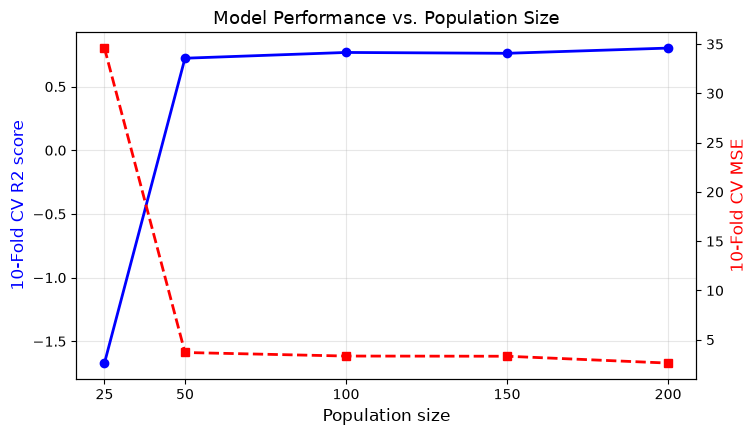

In [69]:
pop_sizes = [25, 50, 100, 150, 200]
pop_r2_scores = []
pop_mse_scores = []

print(f"{'Population Size':<18} | {'10-Fold CV R2':<15} | {'10-Fold CV MSE':<15}")
print("-" * 50)
for pop in pop_sizes:
    r2, mse = evaluate_gp(population_size=pop)
    pop_r2_scores.append(r2)
    pop_mse_scores.append(mse)
    print(f"{pop:<18d} | {r2:<15.4f} | {mse:<15.4f}")

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax2 = ax1.twinx()
ax1.plot(pop_sizes, pop_r2_scores, 'b-o', label='R2 Score', linewidth=2)
ax2.plot(pop_sizes, pop_mse_scores, 'r--s', label='MSE', linewidth=2)
ax1.set_xlabel('Population size', fontsize=12)
ax1.set_ylabel('10-Fold CV R2 score', color='b', fontsize=12)
ax2.set_ylabel('10-Fold CV MSE', color='r', fontsize=12)
ax1.set_title('Model Performance vs. Population Size', fontsize=13)
ax1.set_xticks(pop_sizes)
ax1.grid(True, alpha=0.3)
plt.show()

Observations:
* Effect: Increasing population_size from 25 to 200 leads to substantial improvements in model performance up to r2 of 0.8025
* Lecture Baseline model utilizes maximum population size with best r2 (and MSE of 2.6306)

---
### Hyperparameter 2: Number of Generations
Testing generations amount of `[5, 10, 15, 20]`.


Generations     | 10-Fold CV R2   | 10-Fold CV MSE 
--------------------------------------------------
5               | 0.7163          | 3.8581         
10              | 0.7645          | 3.0885         
15              | 0.7930          | 2.7796         
20              | 0.8025          | 2.6306         


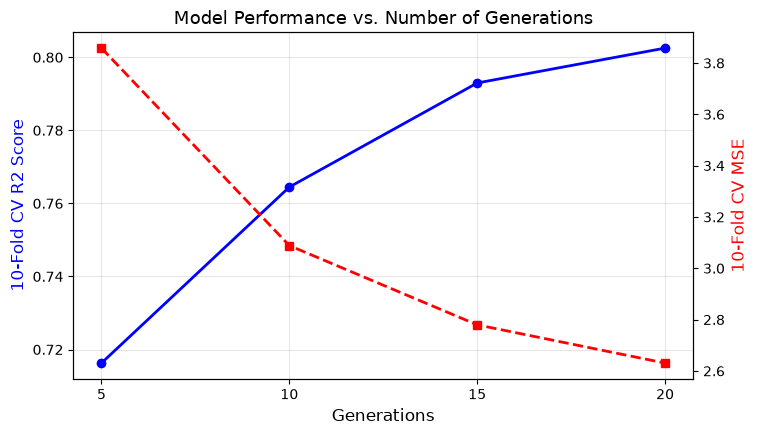

In [70]:
gen_values = [5, 10, 15, 20]
gen_r2_scores = []
gen_mse_scores = []

print(f"{'Generations':<15} | {'10-Fold CV R2':<15} | {'10-Fold CV MSE':<15}")
print("-" * 50)
for gen in gen_values:
    r2, mse = evaluate_gp(generations=gen)
    gen_r2_scores.append(r2)
    gen_mse_scores.append(mse)
    print(f"{gen:<15d} | {r2:<15.4f} | {mse:<15.4f}")

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax2 = ax1.twinx()
ax1.plot(gen_values, gen_r2_scores, 'b-o', label='R2 Score', linewidth=2)
ax2.plot(gen_values, gen_mse_scores, 'r--s', label='MSE', linewidth=2)
ax1.set_xlabel('Generations', fontsize=12)
ax1.set_ylabel('10-Fold CV R2 Score', color='b', fontsize=12)
ax2.set_ylabel('10-Fold CV MSE', color='r', fontsize=12)
ax1.set_title('Model Performance vs. Number of Generations', fontsize=13)
ax1.set_xticks(gen_values)
ax1.grid(True, alpha=0.3)
plt.show()

Observations:
* Effect: The validation R2 score improves monotonically up to 0.8025 at 20 generations, with MSE decreasing 2.6306
* Same as with population size, the best amount of generations is used in the lecture baseline model.

---
### Hyperparameter 3: Tournament  Size
Testing tournament sizes `[2, 5, 10, 20, 50, 100]`.


Tournament size    | 10-Fold CV R2   | 10-Fold CV MSE 
--------------------------------------------------
2                  | 0.0553          | 13.5876        
5                  | 0.7518          | 3.3013         
10                 | 0.8150          | 2.6167         
20                 | 0.8025          | 2.6306         
50                 | 0.7023          | 4.0438         
100                | 0.7895          | 2.8393         


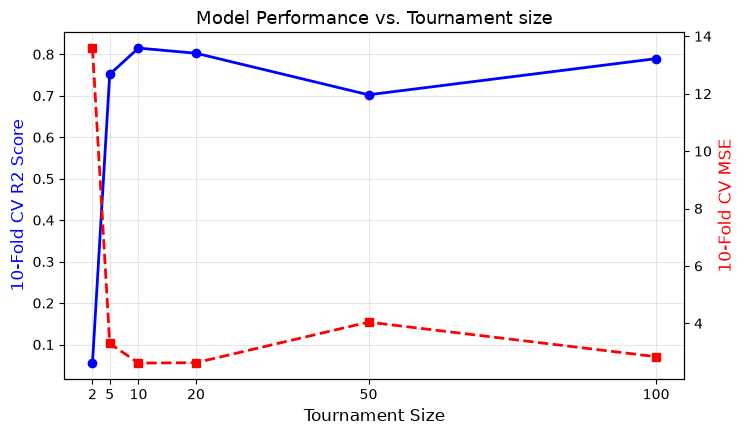

In [71]:
tour_sizes = [2, 5, 10, 20, 50, 100]
tour_r2_scores = []
tour_mse_scores = []

print(f"{'Tournament size':<18} | {'10-Fold CV R2':<15} | {'10-Fold CV MSE':<15}")
print("-" * 50)
for t in tour_sizes:
    r2, mse = evaluate_gp(tournament_size=t)
    tour_r2_scores.append(r2)
    tour_mse_scores.append(mse)
    print(f"{t:<18d} | {r2:<15.4f} | {mse:<15.4f}")

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax2 = ax1.twinx()
ax1.plot(tour_sizes, tour_r2_scores, 'b-o', label='R2 score', linewidth=2)
ax2.plot(tour_sizes, tour_mse_scores, 'r--s', label='MSE', linewidth=2)
ax1.set_xlabel('Tournament Size', fontsize=12)
ax1.set_ylabel('10-Fold CV R2 Score', color='b', fontsize=12)
ax2.set_ylabel('10-Fold CV MSE', color='r', fontsize=12)
ax1.set_title('Model Performance vs. Tournament size', fontsize=13)
ax1.set_xticks(tour_sizes)
ax1.grid(True, alpha=0.3)
plt.show()

Observations:
* Effects: A low tournament size performs poorly. Performance peaks at moderate tournament sizes from 10 to 20, with maximum R2 of 0.8150, while very high sizes like 50 show a drop in generalization performance.
* Using a little smaller tournament size of 10 improves the R2 Score of the model against the lecture baseline model.

---
### Hyperparameter 4: Function Set
The function set specifies the mathematical operators available to construct expression trees. Evaluating sets ranging from basic arithmetic to advanced nonlinear and trigonometric functions.


Function Set Configuration               | 10-Fold CV R2   | 10-Fold CV MSE 
----------------------------------------------------------------------
Arithmetic (add, sub, mul, div)          | 0.7406          | 3.5368         
Arithmetic + Sqrt                        | 0.7552          | 3.3278         
Arithmetic + Sqrt + Log                  | 0.7357          | 3.5649         
Lecture Baseline                         | 0.8025          | 2.6306         
All + Trig (sin, cos)                    | 0.7141          | 3.7559         
Arithmetic + Max/Min/Abs                 | 0.7964          | 2.7706         
All + Max/Min/Abs                        | 0.7493          | 3.4280         
All + Trig + Max/Min/Abs                 | 0.6958          | 4.2529         


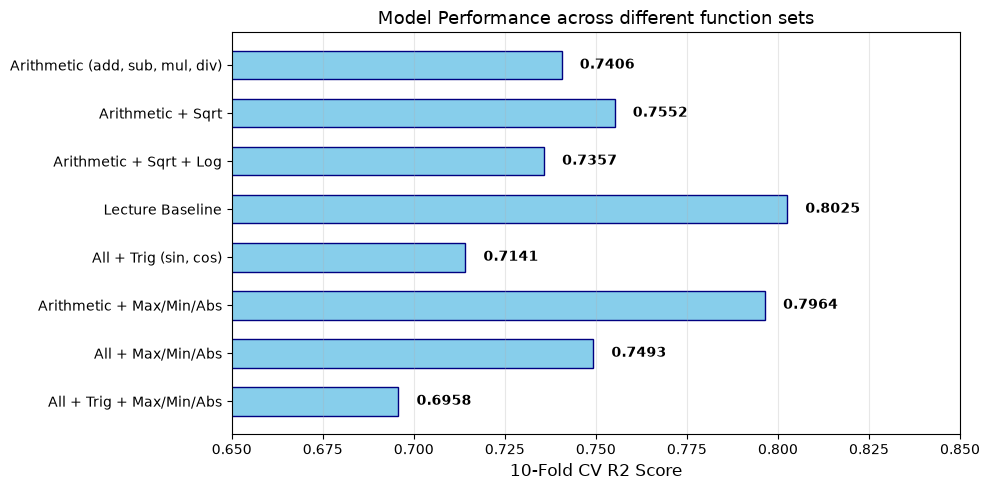

In [72]:
function_sets = {
    'Arithmetic (add, sub, mul, div)': ('add', 'sub', 'mul', 'div'),
    'Arithmetic + Sqrt': ('add', 'sub', 'mul', 'div', 'sqrt'),
    'Arithmetic + Sqrt + Log': ('add', 'sub', 'mul', 'div', 'sqrt', 'log'),
    'Lecture Baseline': ('add', 'sub', 'mul', 'div', 'sqrt', 'log', 'inv'),
    'All + Trig (sin, cos)': ('add', 'sub', 'mul', 'div', 'sqrt', 'log', 'inv', 'sin', 'cos'),
    'Arithmetic + Max/Min/Abs': ('add', 'sub', 'mul', 'div', 'max', 'min', 'abs'),
    'All + Max/Min/Abs': ('add', 'sub', 'mul', 'div', 'sqrt', 'log', 'inv', 'max', 'min', 'abs'),
    'All + Trig + Max/Min/Abs': ('add', 'sub', 'mul', 'div', 'sqrt', 'log', 'inv', 'sin', 'cos', 'max', 'min', 'abs'),
}

fn_names = list(function_sets.keys())
fn_r2_scores = []
fn_mse_scores = []

print(f"{'Function Set Configuration':<40} | {'10-Fold CV R2':<15} | {'10-Fold CV MSE':<15}")
print("-" * 70)
for name, fns in function_sets.items():
    r2, mse = evaluate_gp(function_set=fns)
    fn_r2_scores.append(r2)
    fn_mse_scores.append(mse)
    print(f"{name:<40} | {r2:<15.4f} | {mse:<15.4f}")

plt.figure(figsize=(10, 5))
x_pos = np.arange(len(fn_names))
plt.barh(x_pos, fn_r2_scores, color='skyblue', edgecolor='navy', height=0.6)
plt.yticks(x_pos, fn_names, fontsize=10)
plt.xlabel('10-Fold CV R2 Score', fontsize=12)
plt.title('Model Performance across different function sets', fontsize=13)
plt.xlim(0.65, 0.85)
for i, v in enumerate(fn_r2_scores):
    plt.text(v + 0.005, i, f"{v:.4f}", va='center', fontweight='bold', fontsize=10)
plt.grid(True, axis='x', alpha=0.3)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Observations:
* Effects: Basic arithmetic yields R2 0.7406. Adding sqrt and log functions improves it to 0.7552, and adding inv (inverse) yields the highest performance R^2 = 0.8025. Conversely, adding trigonometric functions or max/min/abs sharply reduces performance down to 0.6958.
* Therefore the lecture baseline model already utilizes the best set of functions.

---
### Hyperparameter 5: Parsimony Coefficient
The parsimony coefficient penalizes large, overly complex trees to prevent bloat (the growth of tree size without significant fitness gain). Testing the coefficents `[0.0, 0.0001, 0.0005, 0.0008, 0.001, 0.002, 0.005, 0.01, 0.05]`.


Parsimony Coefficient     | 10-Fold CV R2   | 10-Fold CV MSE 
--------------------------------------------------
0.0000                    | 0.7756          | 3.1316         
0.0001                    | 0.8209          | 2.3918         
0.0005                    | 0.8159          | 2.4527         
0.0008                    | 0.8200          | 2.3706         
0.0010                    | 0.8025          | 2.6306         
0.0020                    | 0.7954          | 2.7114         
0.0050                    | 0.7843          | 2.8887         
0.0100                    | 0.7673          | 3.1173         
0.0500                    | 0.7698          | 3.0419         


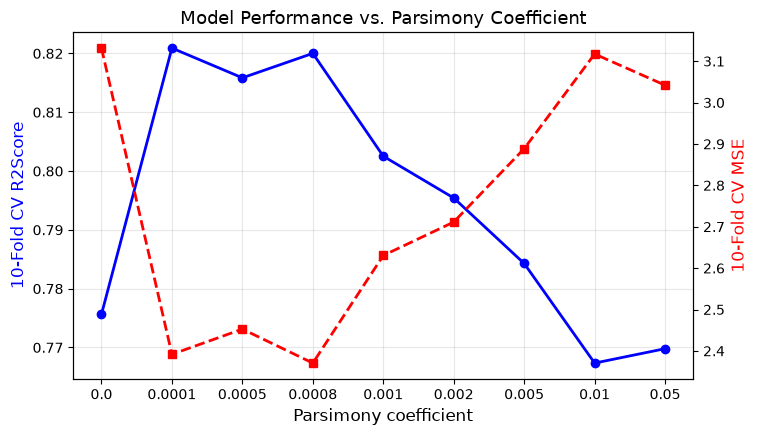

In [73]:
parsimony_vals = [0.0, 0.0001, 0.0005, 0.0008, 0.001, 0.002, 0.005, 0.01, 0.05]
pars_r2_scores = []
pars_mse_scores = []

print(f"{'Parsimony Coefficient':<25} | {'10-Fold CV R2':<15} | {'10-Fold CV MSE':<15}")
print("-" * 50)
for p in parsimony_vals:
    r2, mse = evaluate_gp(parsimony_coefficient=p)
    pars_r2_scores.append(r2)
    pars_mse_scores.append(mse)
    print(f"{p:<25.4f} | {r2:<15.4f} | {mse:<15.4f}")

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax2 = ax1.twinx()
ax1.plot([str(p) for p in parsimony_vals], pars_r2_scores, 'b-o', label='R2 Score', linewidth=2)
ax2.plot([str(p) for p in parsimony_vals], pars_mse_scores, 'r--s', label='MSE', linewidth=2)
ax1.set_xlabel('Parsimony coefficient', fontsize=12)
ax1.set_ylabel('10-Fold CV R2Score', color='b', fontsize=12)
ax2.set_ylabel('10-Fold CV MSE', color='r', fontsize=12)
ax1.set_title('Model Performance vs. Parsimony Coefficient', fontsize=13)
ax1.grid(True, alpha=0.3)
plt.show()

Observations:
* Effects: Without parsimony penalty, the model achieves R2 = 0.7756. Introducing a slight penalty increases the R2 Score achieving the lowest overall MSE = 2.3706 and almost highest R2 0.8200 (trade off). Setting the penalty too high penalizes structural complexity excessively, causing underfitting.
* Inducing a parsimony penalty of 0.0008 can improve the model performance.

---
## 3. Optimized Model vs. Lecture Baseline Model

Combining the findings into the final optimized model and comparing it directly with the lecture baseline model.
* Baseline: population_size=200, generations=20, tournament_size=20, parsimony_coefficient='auto', function_set=('add', 'sub', 'mul', 'div', 'sqrt', 'log', 'inv')
* Optimized: population_size=200, generations=20, tournament_size=10, parsimony_coefficient=0.0008, function_set=('add', 'sub', 'mul', 'div', 'sqrt', 'log', 'inv')


In [74]:
best_model = SymbolicRegressor(
    population_size=200,
    generations=20,
    tournament_size=10,
    init_depth=(2, 6),
    const_range=(-10, 10),
    metric='mse',
    function_set=('add', 'sub', 'mul', 'div', 'sqrt', 'log', 'inv'),
    stopping_criteria=0.01,
    p_crossover=0.75,
    p_subtree_mutation=0.1,
    p_point_mutation=0.1,
    parsimony_coefficient=0.0008,
    max_samples=1,
    warm_start=False,
    feature_names=feature_names,
    random_state=42
)
best_pipeline = make_pipeline(StandardScaler(), best_model)
best_pipeline.fit(X, y)

best_r2, best_mse = evaluate_gp(parsimony_coefficient=0.0008)

print("=" * 60)
print(f"{'Model Configuration':<30} | {'10-Fold CV R2':<12} | {'10-Fold CV MSE':<12}")
print("-" * 60)
print(f"{'Lecture Baseline':<30} | {base_r2:<12.4f} | {base_mse:<12.4f}")
print(f"{'Optimized Model':<30} | {best_r2:<12.4f} | {best_mse:<12.4f}")
print("=" * 60)

print("\nBest Symbolic Expression tree:")
print(best_pipeline[-1]._program)

Model Configuration            | 10-Fold CV R2 | 10-Fold CV MSE
------------------------------------------------------------
Lecture Baseline               | 0.8025       | 2.6306      
Optimized Model                | 0.8200       | 2.3706      

Best Symbolic Expression tree:
add(sub(add(add(sub(9.843, -2.168), weight_kg), weight_kg), model_year), displacement)


### Prediction Performance Visualization

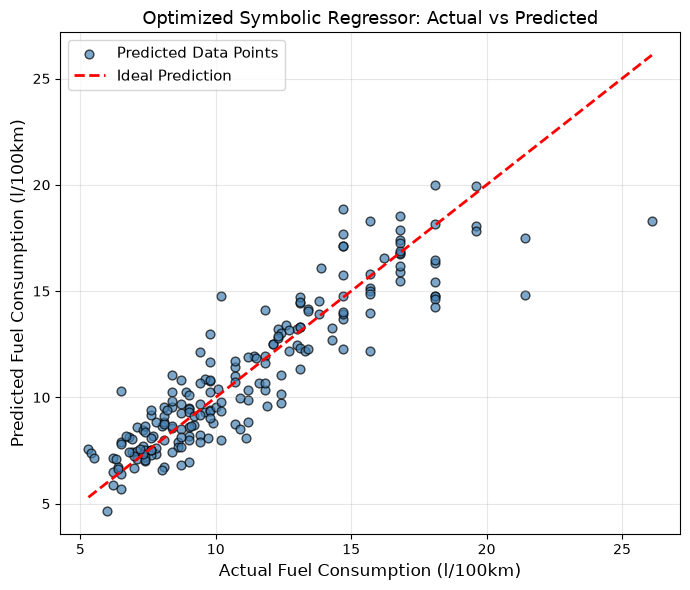

In [75]:
y_pred_cv = cross_val_predict(best_pipeline, X, y, cv=10)

plt.figure(figsize=(7, 6))
plt.scatter(y, y_pred_cv, color='steelblue', edgecolor='k', alpha=0.7, s=40, label='Predicted Data Points')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', linewidth=2, label='Ideal Prediction')
plt.xlabel('Actual Fuel Consumption (l/100km)', fontsize=12)
plt.ylabel('Predicted Fuel Consumption (l/100km)', fontsize=12)
plt.title(f'Optimized Symbolic Regressor: Actual vs Predicted', fontsize=13)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

## Final Analysis and Conclusions
### 1. Effect of hyperparameters on model performance:
- Population Size: Larger population sizes steadily improve R2 and reduce MSE since Genetic Programming relies on a diverse set of building blocks. Small populations suffer from premature convergence while larger population provides broad parallel exploratiion of expression structures.
- Number of Generations: Performance consistently climbs with more generations because evolutionary recombination and mutation require multiple successive cycles to discover, refine and assemble useful mathematical sub-expressions while removing destructive terms.
- Tournament Size: Displays a non-monotonic sweet-spot behavior. Very low tournament size fails due to insufficent selection pressure resulting in near-random walk without exploiting promising solutions. Intermediate sizes achieve optimal performance whereas larger sizes degrade generalization performance due to elimination of population diversity and trapping in local optimas.
- Function set: The baseline model set containing arithmetic, sqrt, log and inverse functions achieves the best domain fit. Both omitting inv/sqrt/log and adding trigonometric or max/min/abs operators severly degrades performance. That relates to fuel consumption being physically governed by inverse and power-law relationships.
- Parsimony Coefficient: Setting the coefficient on a calibrated sweet-spot yields the highest predictive accuracy. A small penalty effectively controls tree bloat and prevents overfitting by favoring concise, generalizable expressions without overly restricting necessary complexity.

### 2. Summary of Best Found Configuration:
* Population Size: 200
* Generations: 20
* Tournament Size: 10
* Function Set: 'add', 'sub', 'mul', 'div', 'sqrt', 'log', 'inv'
* Parsimony Coefficient: 0.0008
* Result: Achieved R2 = 0.8200 and MSE = 2.3706 under 10-fold cross-validation. improving upon the lecture baseline R2 = 0.8025.

---
*Assignee: Jakob Benedikt Wilmesmeier*